In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load Data
df = pd.read_csv("Ecommerce_Purchase_Prediction_DataSet.csv")

Exploratory Data Analysis (EDA)

In [2]:
# Display the first five rows
display(df.head())

# Check the number of rows and columns
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")

# Display the column names
print("column names" , df.columns,"\n\n")

# View column names, data types, non-null counts, and memory usage
print("column names with data types," , df.info(),"\n\n")

# Find missing values.
print("missing values" , df.isnull().sum(),"\n\n")

# Check duplicate records.
print("duplicate records" , display(df[df.duplicated()]),"\n\n")

# Examine numerical columns using statistical summaries.
display(df.describe())

,Customer_ID,Age,Gender,Device_Type,Traffic_Source,Membership_Type,Payment_Method,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
0,CUST00001,37.0,Female,Mobile,Referral,Regular,Credit Card,6.78,5.0,8,0,4933.27,14.05,2,3.09,0.273,4.07,1,1
1,CUST00002,24.0,Male,Mobile,Organic,Premium,Debit Card,12.79,9.0,5,1,3042.60,7.28,2,48.27,0.045,4.19,0,1
2,CUST00003,42.0,Female,Mobile,Referral,Regular,Wallet,11.72,9.0,5,1,NaN,9.77,4,3.82,0.796,3.37,2,0
3,CUST00004,43.0,Male,Tablet,Referral,Premium,UPI,10.67,7.0,6,3,2776.48,6.78,0,9.24,0.426,5.00,1,1
4,CUST00005,18.0,Male,Desktop,Social Media,Regular,Debit Card,12.06,4.0,3,4,3683.66,16.37,4,4.46,0.347,2.16,0,1


Rows: 10000, Columns: 19
column names Index(['Customer_ID', 'Age', 'Gender', 'Device_Type', 'Traffic_Source',
       'Membership_Type', 'Payment_Method', 'Session_Duration_Min',
       'Pages_Viewed', 'Products_Viewed', 'Cart_Items', 'Cart_Value_INR',
       'Discount_Percent', 'Previous_Orders', 'Days_Since_Last_Visit',
       'Email_Open_Rate', 'Customer_Rating', 'Returns_Last_Year', 'Purchase'],
      dtype='str') 


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    9762 non-null   float64
 2   Gender                 9796 non-null   str    
 3   Device_Type            9855 non-null   str    
 4   Traffic_Source         9760 non-null   str    
 5   Membership_Type        9791 non-null   str    
 6   Payment_Method         9787 non-null   str    
 7   Sessio

,Customer_ID,Age,Gender,Device_Type,Traffic_Source,Membership_Type,Payment_Method,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase


duplicate records None 




,Age,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
count,9762.000000,9776.000000,10000.000000,10000.000000,10000.000000,9675.000000,9789.000000,10000.000000,9820.000000,10000.000000,9675.000000,10000.000000,10000.000000
mean,34.127228,13.117865,7.274137,3.991100,1.523000,1912.614298,12.178725,2.997800,13.314532,0.500227,3.778779,0.601300,0.648000
std,9.546429,12.737399,6.055331,1.999555,1.228015,3831.569883,8.143978,1.725947,26.690252,0.290871,0.754031,0.775241,0.477618
min,18.000000,1.000000,1.000000,0.000000,0.000000,14.930000,0.140000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,27.000000,6.780000,5.000000,3.000000,1.000000,819.930000,6.450000,2.000000,3.460000,0.246000,3.270000,0.000000,0.000000
50%,34.000000,10.835000,7.000000,4.000000,1.000000,1433.270000,10.820000,3.000000,8.470000,0.502000,3.800000,0.000000,1.000000
75%,40.000000,16.642500,9.000000,5.000000,2.000000,2279.965000,16.220000,4.000000,16.745000,0.751250,4.340000,1.000000,1.000000
max,74.000000,227.756046,148.075292,12.000000,7.000000,88342.757367,99.149690,15.000000,671.772129,1.000000,5.000000,6.000000,1.000000


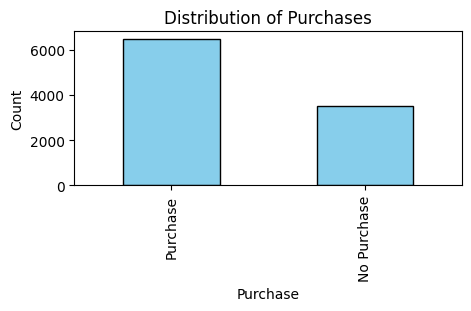

In [3]:
# Visualise the distribution of purchases.
df['Purchase'].map({0: 'No Purchase', 1: 'Purchase'}).value_counts().plot(kind='bar', color='skyblue', edgecolor='black', figsize=(5, 2))

# Add proper title and labels
plt.title('Distribution of Purchases')
plt.xlabel('Purchase')
plt.ylabel('Count')
plt.show()


In [4]:
# Group by Purchase first, then rename the index labels
summary = df.groupby('Purchase').mean(numeric_only=True).rename(index={0: 'No Purchase', 1: 'Purchase'})
display(summary.round(2))


,Age,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year
Purchase,,,,,,,,,,,,
No Purchase,34.14,11.74,6.93,3.70,1.14,1630.08,11.63,2.81,14.88,0.49,3.74,0.65
Purchase,34.12,13.86,7.46,4.15,1.73,2065.42,12.48,3.10,12.46,0.51,3.80,0.57


Classification Report:

              precision    recall  f1-score   support

 No Purchase       0.62      0.39      0.48       704
    Purchase       0.73      0.87      0.79      1296

    accuracy                           0.70      2000
   macro avg       0.67      0.63      0.64      2000
weighted avg       0.69      0.70      0.68      2000



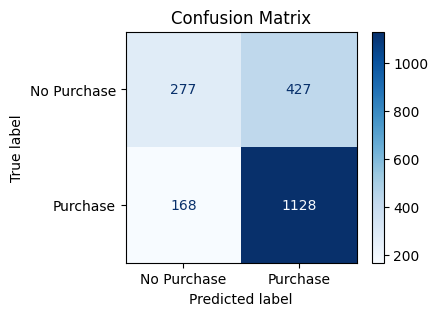

In [6]:
# 2. Separate Features (X) and Target (y)
# Drop 'Customer_ID' as it's just an identifier, and 'Purchase' because it is the answer
X = df.drop(columns=["Purchase", "Customer_ID"])
y = df["Purchase"]

# 3. Split the Data (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# Cap numeric outliers using IQR limits from the training set.
q1 = X_train[num_cols].quantile(0.25)
q3 = X_train[num_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
X_train[num_cols] = X_train[num_cols].clip(lower=lower, upper=upper, axis=1)
X_test[num_cols] = X_test[num_cols].clip(lower=lower, upper=upper, axis=1)

# 4. Handle Missing Values
# Fill numbers with the median, and text/categories with the most frequent value (mode)
X_train[num_cols] = X_train[num_cols].fillna(X_train[num_cols].median())
X_test[num_cols] = X_test[num_cols].fillna(X_train[num_cols].median())

X_train[cat_cols] = X_train[cat_cols].fillna(X_train[cat_cols].mode().iloc[0])
X_test[cat_cols] = X_test[cat_cols].fillna(X_train[cat_cols].mode().iloc[0])

# 5. Convert Categories to Numbers & Scale Data
# get_dummies converts text categories (like "Mobile" or "Desktop") into 1s and 0s
X_train = pd.get_dummies(X_train, columns=cat_cols)
X_test = pd.get_dummies(X_test, columns=cat_cols)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0) # Ensures test columns match train columns

# Scale numerical columns so large numbers don't overwhelm the model
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# 6. Train the Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 7. Evaluate the Model
predictions = model.predict(X_test)
print("Classification Report:\n")
print(classification_report(y_test, predictions, target_names=["No Purchase", "Purchase"]))

# 8. Plot Confusion Matrix
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Purchase', 'Purchase'])

# Set the figure size BEFORE plotting
plt.figure(figsize=(4, 3))

# Draw the plot on the current figure
disp.plot(cmap='Blues', ax=plt.gca()) 

plt.title("Confusion Matrix")
plt.show()